# Campos de Weber en 3D: paridad, corte de rama y reparametrización

**Valores:** $a=-1,0,1$. **Orden de paridades:** primero $\xi$, después $\eta$.
Se representan las cuatro combinaciones **par–par, par–impar, impar–par e impar–impar**
como superficies $z=\psi(x,y)$, con altura de campo real con signo, no como mapas de calor.
La altura de estas figuras es amplitud, **no** la coordenada de propagación del haz.



In [1]:
from pathlib import Path
from functools import lru_cache
import csv
import json
import sys
import numpy as np
import scipy
from scipy.integrate import solve_ivp
import matplotlib
import matplotlib.pyplot as plt
import mpmath as mp
import plotly
import plotly.graph_objects as go
from plotly.subplots import make_subplots
from IPython.display import display, Markdown, HTML

A_VALUES = (-1.0, 0.0, 1.0)
K_T = 0.5                 # reproduce los argumentos U,V de la celda 22 original
SPAN = 12.0              # x,y en [-SPAN,SPAN]; unidades consistentes con k_t
N = 111                  # puntos por eje; aumentar para exportaciones más finas
EXPORTAR = True
MOSTRAR_INTERACTIVO = True
OUT = Path.cwd() / 'Weber_3D_resultados'
if EXPORTAR:
    OUT.mkdir(exist_ok=True)

PARITIES = [('even','even','par–par'), ('even','odd','par–impar'),
            ('odd','even','impar–par'), ('odd','odd','impar–impar')]
LABEL = {('even','even'):'regular', ('even','odd'):'salto de campo',
         ('odd','even'):'arista: salto de derivada', ('odd','odd'):'regular'}
plt.rcParams.update({'font.size':10, 'axes.titlesize':11, 'figure.dpi':110,
                     'savefig.dpi':170, 'axes.spines.top':False,
                     'axes.spines.right':False})
print(f'Python {sys.version.split()[0]} | NumPy {np.__version__} | SciPy {scipy.__version__}')
print(f'k_t={K_T}; a={A_VALUES}; altura=campo real; exportaciones: {OUT}')

Python 3.13.5 | NumPy 2.5.3 | SciPy 1.18.1
k_t=0.5; a=(-1.0, 0.0, 1.0); altura=campo real; exportaciones: /Users/gregoriosainzlombardo/Documents/Codex/2026-10-26/ho/outputs/Weber_3D_resultados


## 1. Soluciones reales con paridad controlada

Definimos $P_p(w;a)$ mediante
$$P''+\left(\frac{w^2}{4}-a\right)P=0,$$
con $(P_e(0),P'_e(0))=(1,0)$ y $(P_o(0),P'_o(0))=(0,1)$.
Las fórmulas equivalentes son
$$P_e(w;a)=e^{iw^2/4}{}_1F_1(\tfrac14+\tfrac{ia}{2};\tfrac12;-iw^2/2),$$
$$P_o(w;a)=w\,e^{iw^2/4}{}_1F_1(\tfrac34+\tfrac{ia}{2};\tfrac32;-iw^2/2).$$
Son reales para argumentos y $a$ reales. En la función `weber_even(q,w)` del original,
$q=-a$ con esta definición. Por eso se conserva el producto original:
$$\psi_{pq}(x,y;a)=P_p(\sqrt{2k_t}\xi;a)\,P_q(\sqrt{2k_t}\eta;-a).$$
Este producto satisface $(\partial_x^2+\partial_y^2+k_t^2)\psi=0$ fuera del corte y del origen.
Usamos integración DOP853 con salida densa para evitar cancelación numérica de las series
de Kummer a argumentos grandes. Más abajo se contrasta con Kummer a 40 dígitos.

In [2]:
@lru_cache(maxsize=48)
def fundamental(a, limit):
    # Integra simultáneamente las soluciones par e impar en w>=0.
    def ode(w, z):
        q = a - w*w/4
        return [z[1], q*z[0], z[3], q*z[2]]
    sol = solve_ivp(ode, (0.0, float(limit)), [1.,0.,0.,1.],
                    method='DOP853', rtol=2e-12, atol=2e-14,
                    dense_output=True, max_step=0.12)
    if not sol.success:
        raise RuntimeError(sol.message)
    return sol

def P(w, a, parity='even', derivative=False):
    if parity not in ('even','odd'):
        raise ValueError('parity debe ser even u odd')
    w = np.asarray(w, dtype=float)
    limit = max(1., float(np.ceil(np.max(np.abs(w)) + 0.25)))
    sol = fundamental(float(a), limit)
    index = (0 if parity == 'even' else 2) + int(derivative)
    values = sol.sol(np.abs(w).ravel())[index].reshape(w.shape)
    if (parity == 'odd') != derivative:
        values = values*np.sign(w)
    return values

def inverse_quadratic(x, y, side=1):
    # Rama xi>=0, eta con signo. side fija el límite en y=0.
    x,y = np.broadcast_arrays(np.asarray(x,float), np.asarray(y,float))
    r = np.hypot(x,y)
    s = np.where(y == 0, float(side), np.sign(y))
    xi = np.sqrt(np.maximum(r+x,0.))
    eta = s*np.sqrt(np.maximum(r-x,0.))
    # Evita pérdida por cancelación en r-|x| cerca del corte.
    np.divide(y, xi, out=eta, where=(x>=0)&(xi>0))
    np.divide(np.abs(y), np.abs(eta), out=xi, where=(x<0)&(eta!=0))
    return xi,eta

def field_quadratic(x,y,a,p,q,side=1):
    xi,eta = inverse_quadratic(x,y,side)
    s = np.sqrt(2*K_T)
    return P(s*xi,a,p)*P(s*eta,-a,q)

def linear_factor(t,a,parity,branch_sign=1):
    # L_e(t;a)=P_e(2 sqrt(t);a), L_o(t;a)=P_o(2 sqrt(t);a), t>=0.
    # La variable lineal no contiene el signo: se transporta como dato de rama.
    t = np.asarray(t,float)
    if np.any(t < 0):
        raise ValueError('t>=0 requerido')
    result = P(2*np.sqrt(t),a,parity)
    return result*(branch_sign if parity == 'odd' else 1.)

def inverse_linear(x,y,side=1):
    xi,eta = inverse_quadratic(x,y,side)
    u,v = xi**2/np.sqrt(2), eta**2/np.sqrt(2)
    branch = np.where(np.asarray(y)==0, float(side), np.sign(y))
    return u,v,branch

def field_linear(x,y,a,p,q,side=1):
    u,v,branch = inverse_linear(x,y,side)
    t,s = K_T*u/np.sqrt(2), K_T*v/np.sqrt(2)
    return linear_factor(t,a,p)*linear_factor(s,-a,q,branch)

def save_show(fig,name):
    if EXPORTAR:
        fig.savefig(OUT/f'{name}.png',bbox_inches='tight',facecolor='white')
    plt.show()
    plt.close(fig)

## 2. Coordenadas lineales: la reparametrización exacta

Llamamos $(u,v)$ a sus coordenadas lineales:
$$x=\frac{u-v}{\sqrt2},\qquad y=\sigma_\xi\sigma_\eta\sqrt{2uv},\qquad u,v\geq0.$$
La conexión con las cuadráticas es
$$\boxed{u=\xi^2/\sqrt2,\quad v=\eta^2/\sqrt2},\qquad
\xi=\sigma_\xi 2^{1/4}\sqrt u,\quad\eta=\sigma_\eta 2^{1/4}\sqrt v.$$
Aquí $\sigma_\xi=+1$ y $\sigma_\eta$ identifica el semiplano. Sin estos signos,
$y=\sqrt{2uv}$ sólo cubre el semiplano superior. El cambio por cuadrados no es
globalmente invertible si se olvidan las ramas.

Con $t=k_tu/\sqrt2$ tenemos $w=\sqrt{2k_t}\xi=2\sigma_\xi\sqrt t$.
Si $L(t)=P(2\sqrt t)$, la regla de la cadena da
$$\frac{d^2P}{dw^2}=tL''+\tfrac12L',\qquad
tL''+\tfrac12L'+(t-a)L=0.$$
Para $t>0$, $L''+L'/(2t)+(1-a/t)L=0$: la ecuación en la variable lineal.
:
$$L_e=e^{it}{}_1F_1(\tfrac14+\tfrac{ia}{2};\tfrac12;-2it),$$
$$L_o=2\sqrt t\,e^{it}{}_1F_1(\tfrac34+\tfrac{ia}{2};\tfrac32;-2it).$$


In [3]:
# Controles independientes: Kummer con precisión alta, geometría y EDO lineal.
rng = np.random.default_rng(1804)
max_kummer_error = 0.
max_linear_kummer_error = 0.
with mp.workdps(40):
    for a in A_VALUES:
        for parity in ('even','odd'):
            b,c = (mp.mpf('0.25'),mp.mpf('0.5')) if parity=='even' else (mp.mpf('0.75'),mp.mpf('1.5'))
            for w in np.r_[0., -0.02, np.linspace(-8,8,19)]:
                z = mp.mpf(float(w))
                ref = mp.exp(1j*z*z/4)*mp.hyp1f1(b+0.5j*a,c,-0.5j*z*z)
                if parity=='odd': ref *= z
                assert abs(mp.im(ref)) < mp.mpf('1e-30')
                err = abs(float(P(w,a,parity))-float(mp.re(ref)))/(1+abs(float(mp.re(ref))))
                max_kummer_error = max(max_kummer_error,err)
            for t in (0.,1e-6,0.03,0.5,2.,7.,16.):
                tm=mp.mpf(t)
                ref = mp.exp(1j*tm)*mp.hyp1f1(b+0.5j*a,c,-2j*tm)
                if parity=='odd': ref *= 2*mp.sqrt(tm)
                err=abs(float(linear_factor(t,a,parity))-float(mp.re(ref)))/(1+abs(float(mp.re(ref))))
                max_linear_kummer_error=max(max_linear_kummer_error,err)
assert max(max_kummer_error,max_linear_kummer_error) < 1e-9

xcheck,ycheck = rng.uniform(-SPAN,SPAN,(2,150))
xi,eta = inverse_quadratic(xcheck,ycheck)
u,v,branch = inverse_linear(xcheck,ycheck)
geometry_error = max(np.max(abs(xcheck-(u-v)/np.sqrt(2))),
                     np.max(abs(ycheck-branch*np.sqrt(2*u*v))))
assert geometry_error < 1e-11
reparam_error = 0.
for a in A_VALUES:
    for p,q,_ in PARITIES:
        fq=field_quadratic(xcheck,ycheck,a,p,q)
        fl=field_linear(xcheck,ycheck,a,p,q)
        reparam_error=max(reparam_error,float(np.max(abs(fq-fl))))
assert reparam_error < 1e-9

# Residuo de la EDO lineal mediante derivadas de Kummer (mp.diff), no del integrador.
linear_ode_residual=0.
with mp.workdps(40):
    for a in A_VALUES:
        for odd in (False,True):
            def L(t):
                b,c=(mp.mpf('.75'),mp.mpf('1.5')) if odd else (mp.mpf('.25'),mp.mpf('.5'))
                return (2*mp.sqrt(t) if odd else 1)*mp.exp(1j*t)*mp.hyp1f1(b+.5j*a,c,-2j*t)
            for t in map(mp.mpf,('.01','.3','2','8')):
                residual=t*mp.diff(L,t,2)+mp.diff(L,t)/2+(t-a)*L(t)
                linear_ode_residual=max(linear_ode_residual,float(abs(residual)))
assert linear_ode_residual < 1e-25

# Helmholtz cartesiana: diferencias centradas independientes, lejos del corte/origen.
# Reducir h a la mitad debe reducir el residuo de truncamiento de orden dos.
xp=np.array([-3.2,-1.4,.7,2.8,4.1])
yp=np.array([1.1,-2.3,1.7,-.8,2.4])
helmholtz_errors=[]
for h in (0.004,0.002):
    worst=0.
    for a in A_VALUES:
        for p,q,_ in PARITIES:
            f=lambda x,y:field_quadratic(x,y,a,p,q)
            f0=f(xp,yp)
            lap=(f(xp+h,yp)+f(xp-h,yp)+f(xp,yp+h)+f(xp,yp-h)-4*f0)/h**2
            worst=max(worst,float(np.max(abs(lap+K_T**2*f0)/(1+abs(f0)))))
    helmholtz_errors.append(worst)
assert helmholtz_errors[-1]<1e-6
assert helmholtz_errors[-1]<.4*helmholtz_errors[0]
print(f'Error relativo escalado EDO/Kummer: {max_kummer_error:.3e}')
print(f'Error lineal/Kummer directo:        {max_linear_kummer_error:.3e}')
print(f'Residuo EDO lineal (40 dígitos):    {linear_ode_residual:.3e}')
print(f'Error geométrico:                  {geometry_error:.3e}')
print(f'Error de campo por reparametrizar:  {reparam_error:.3e}')
print(f'Residuo Helmholtz h y h/2:          {helmholtz_errors}')

Error relativo escalado EDO/Kummer: 1.954e-12
Error lineal/Kummer directo:        8.091e-13
Residuo EDO lineal (40 dígitos):    1.837e-40
Error geométrico:                  5.329e-15
Error de campo por reparametrizar:  6.245e-15
Residuo Helmholtz h y h/2:          [2.9084798564015143e-07, 7.285218580309096e-08]


## 3. Superficies 3D en el plano físico: coordenadas cuadráticas

Cada figura contiene las cuatro paridades para un valor de $a$. Se usa una escala
vertical común a las cuatro dentro de cada figura, $\psi/C_a$, donde $C_a$ es el máximo
muestreado de $|\psi|$ entre esos cuatro campos en el dominio mostrado.
Esto **no** es una normalización integral de energía ni la normalización delta del artículo.
Los valores de $C_a$ se imprimen y se conservan para las figuras lineales.

Los dos semiplanos se dibujan como superficies independientes con colores uniformes:
azul para $y\geq0$, naranja para $y\leq0$. El color identifica la rama, no la amplitud.
Sus bordes muestran los límites laterales exactos en $y=0$; no se interpola a través del corte.
El semieje de corte se señala en la base. Las aristas se examinan con mayor aumento después.

Escalas C_a: {-1.0: 4.5177072329939865, 0.0: 2.637594296927411, 1.0: 4.5177072329939865}


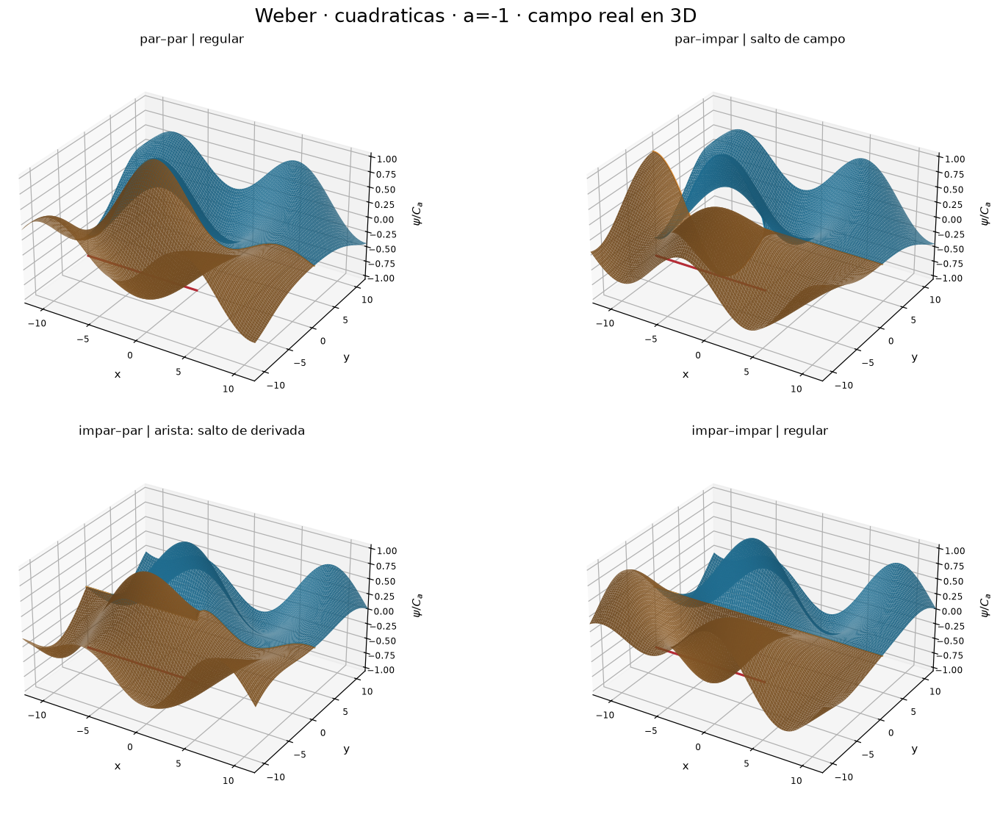

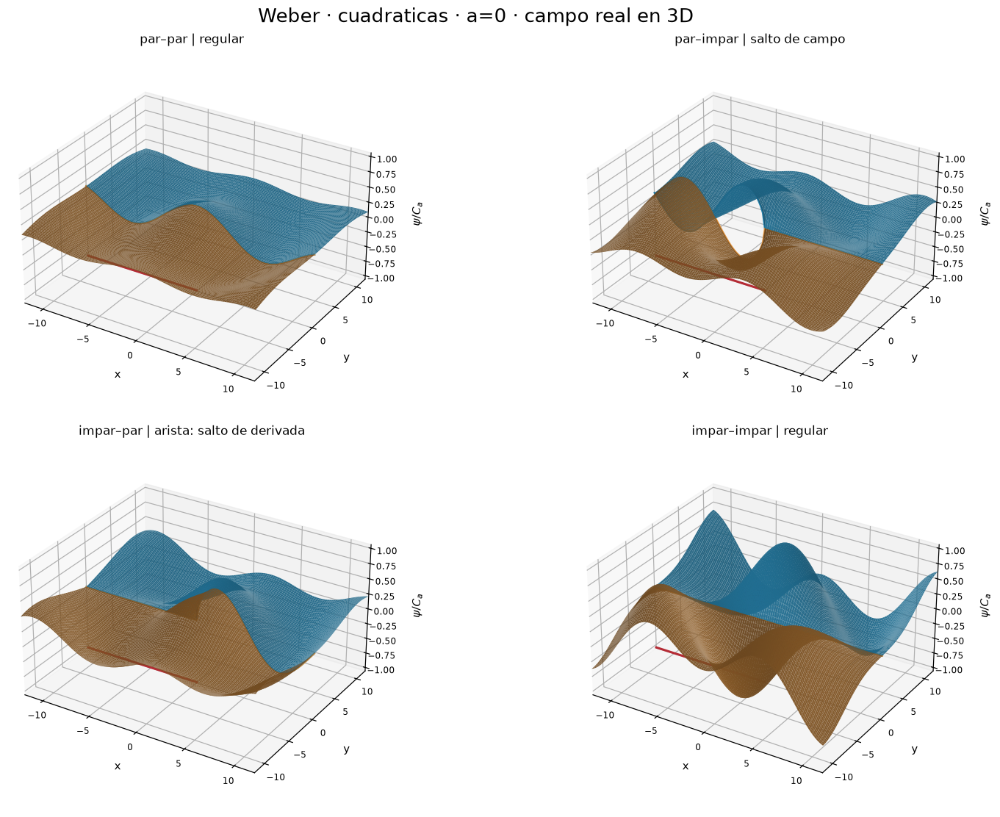

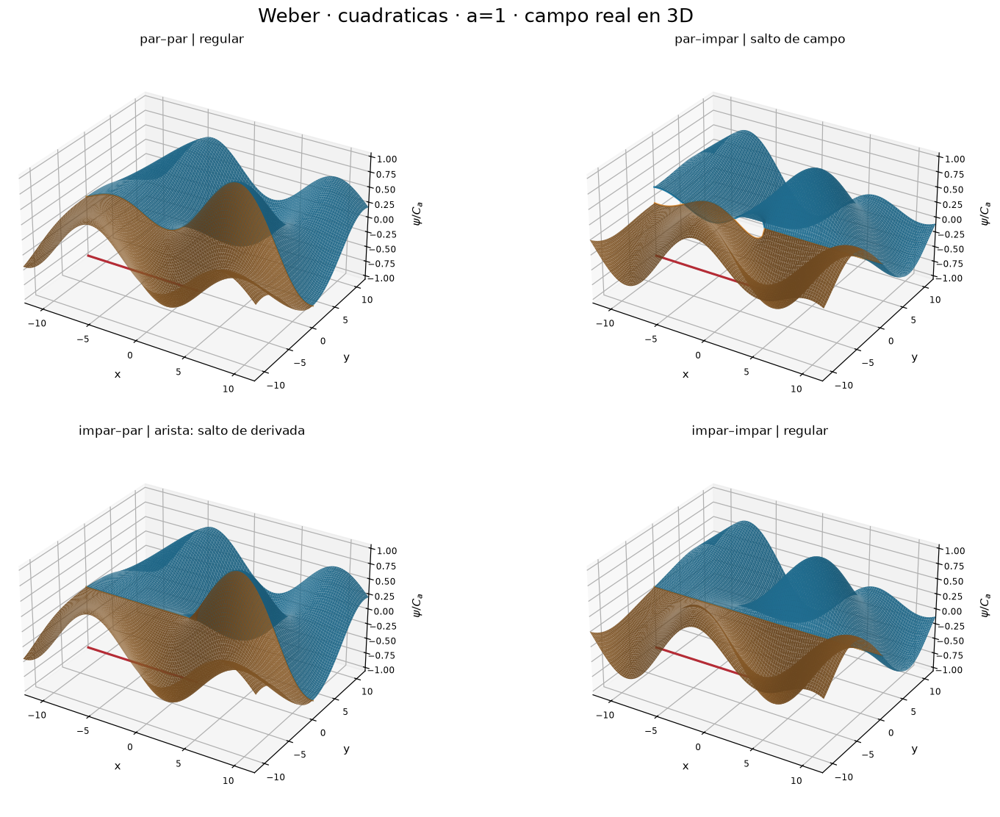

In [4]:
axis = np.linspace(-SPAN,SPAN,N)
half_y = np.linspace(0.,SPAN,(N+1)//2)
X,Yp = np.meshgrid(axis,half_y)
Ym = -Yp
SCALES = {}
for a in A_VALUES:
    SCALES[a] = max(float(np.max(abs(field_quadratic(X,Y,a,p,q,side))))
                    for p,q,_ in PARITIES for Y,side in ((Yp,1),(Ym,-1)))
print('Escalas C_a:',SCALES)

def style_3d(ax,title,zlim=(-1.06,1.06),xlim=None,ylim=None):
    ax.set(title=title,xlabel='x',ylabel='y',zlabel=r'$\psi/C_a$')
    ax.set_zlim(*zlim)
    if xlim: ax.set_xlim(*xlim)
    if ylim: ax.set_ylim(*ylim)
    ax.view_init(elev=29,azim=-58)
    ax.set_box_aspect((1.2,1.,0.65))
    ax.tick_params(labelsize=8,pad=0)

def atlas(system,a):
    fun = field_quadratic if system=='cuadraticas' else field_linear
    fig=plt.figure(figsize=(14,10),layout='constrained')
    fig.suptitle(f'Weber · {system} · a={a:g} · campo real en 3D',fontsize=17)
    for i,(p,q,name) in enumerate(PARITIES,1):
        ax=fig.add_subplot(2,2,i,projection='3d')
        for Y,side,color in ((Yp,1,'#2783ad'),(Ym,-1,'#df9441')):
            z=fun(X,Y,a,p,q,side)/SCALES[a]
            ax.plot_surface(X,Y,z,color=color,linewidth=0,antialiased=True,
                            rcount=len(Y),ccount=N,alpha=.94)
            ax.plot(axis,np.zeros_like(axis),z[0],color=color,lw=1.5)
        ax.plot([-SPAN,0],[0,0],[-1.05,-1.05],color='#b52b35',lw=2)
        style_3d(ax,f'{name} | {LABEL[p,q]}',xlim=(-SPAN,SPAN),ylim=(-SPAN,SPAN))
    save_show(fig,f'{system}_a_{a:+g}')

for a in A_VALUES:
    atlas('cuadraticas',a)

## 4. Las mismas cuatro paridades en coordenadas lineales

Se evalúan `field_linear`, las variables $u,v$ y los signos de rama, manteniendo el mismo
dominio físico y los mismos $C_a$. Las alturas deben coincidir con las figuras anteriores:
eso es precisamente la equivalencia por reparametrización. El prefactor impar de la
representación lineal se conserva como $\sqrt t$ y se restituye su signo al pegar los semiplanos.

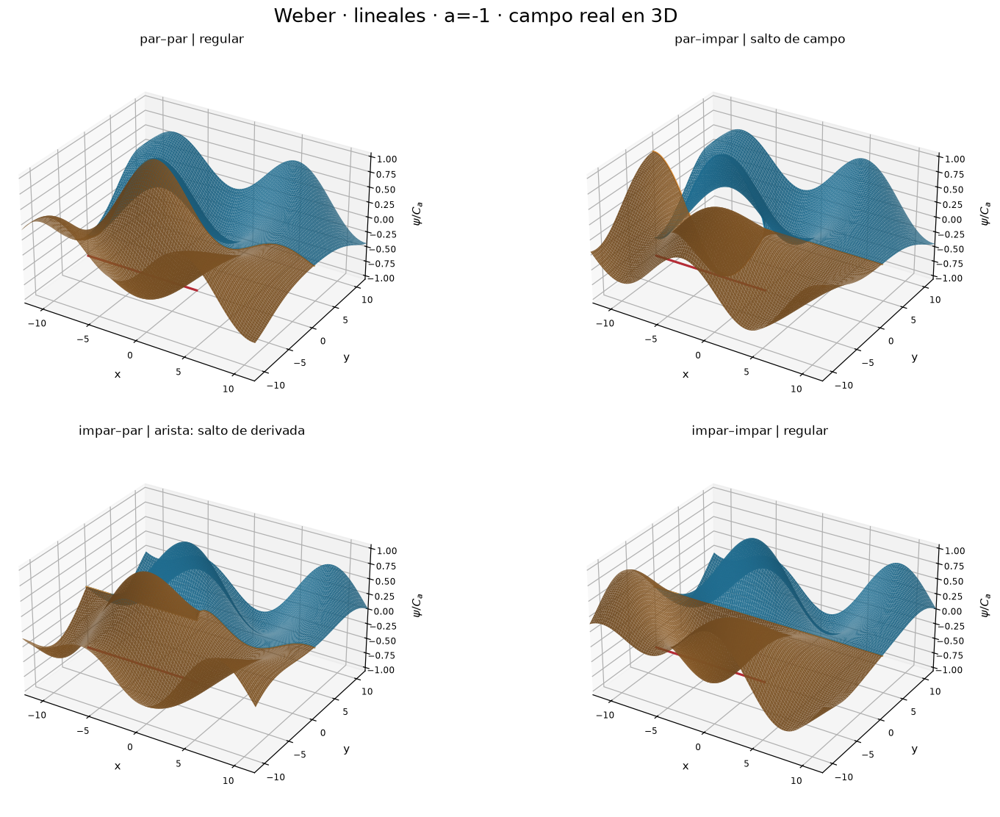

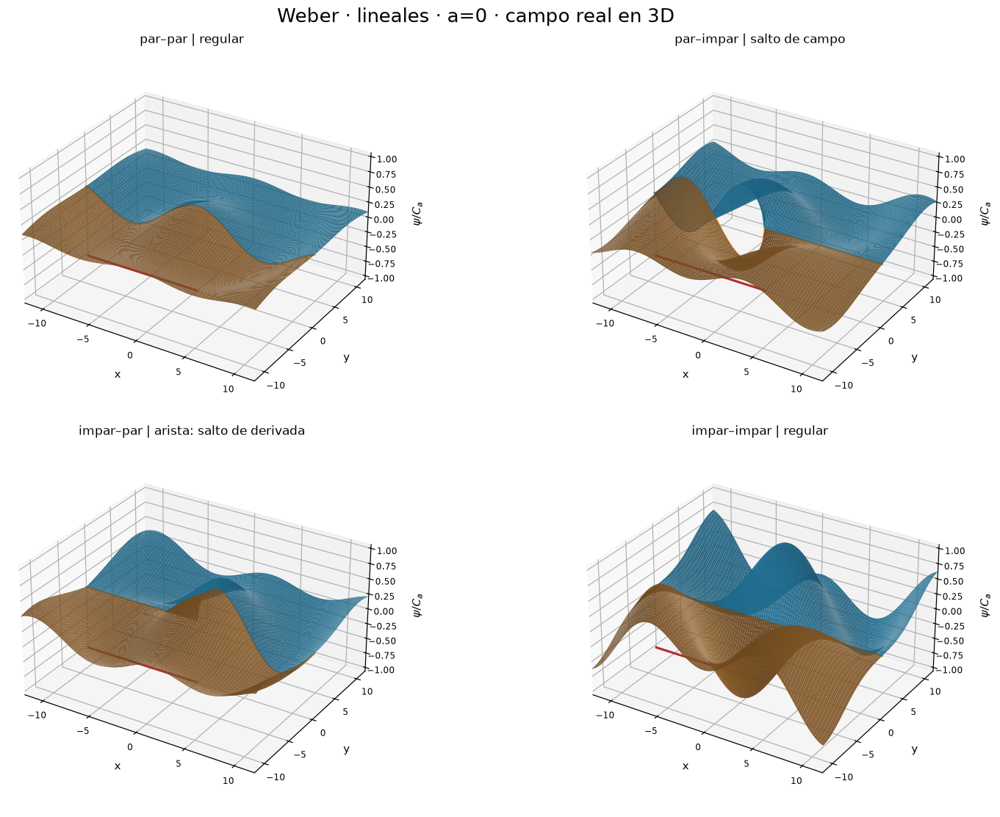

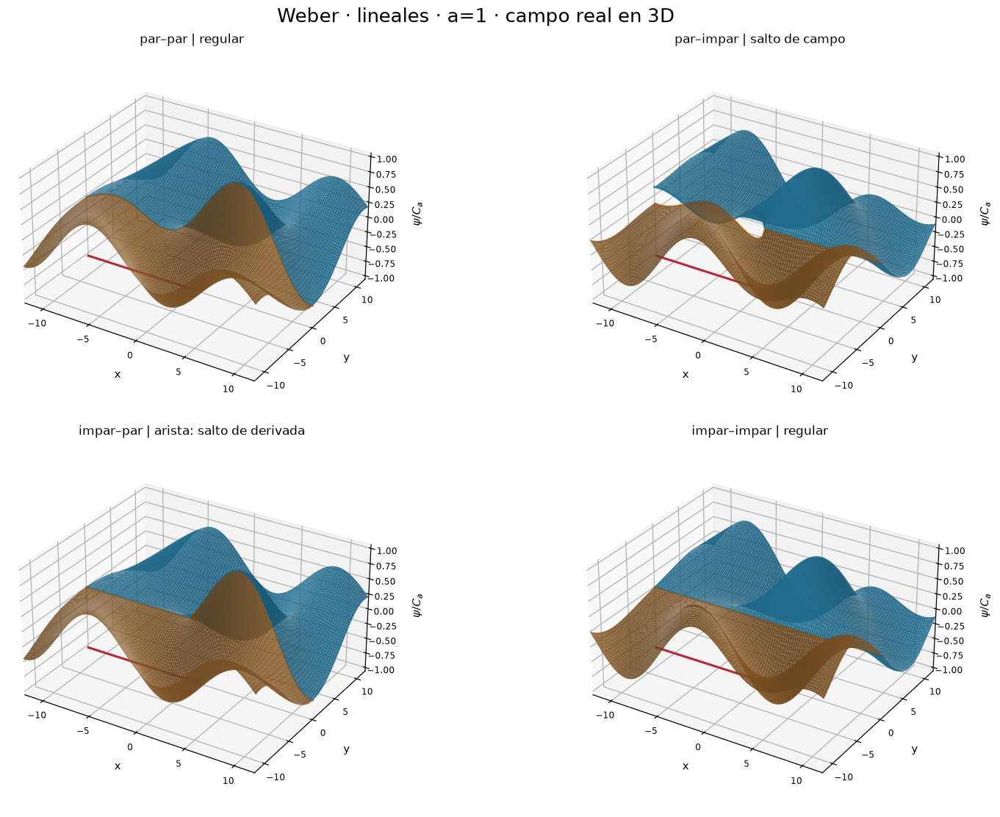

In [5]:
for a in A_VALUES:
    atlas('lineales',a)

## 7. Ver la reparametrización sin cambiar el campo

Izquierda: una curva de coordenada constante dibujada con ambos parámetros.
Derecha: superficie cuadrática y muestras lineales sobrepuestas para la combinación
impar–par con $a=1$. Se muestran ambos semiplanos y se mantienen los signos de rama.
La coincidencia es geométrica y de campo, no sólo de intensidad.

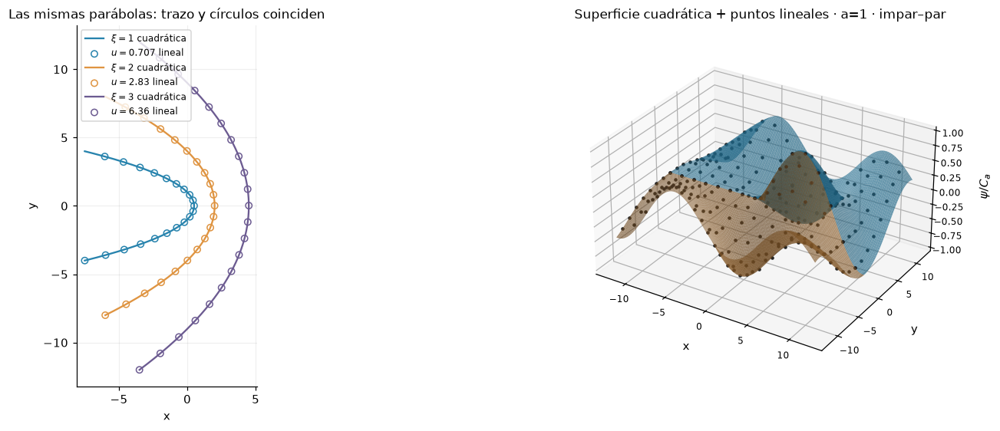

In [9]:
fig=plt.figure(figsize=(14,5),layout='constrained')
ax=fig.add_subplot(1,2,1)
eta_curve=np.linspace(-4,4,500)
for xi0,color in ((1.,'#2783ad'),(2.,'#df9441'),(3.,'#6c5b91')):
    u0=xi0**2/np.sqrt(2)
    vcurve=eta_curve**2/np.sqrt(2)
    xq=(xi0**2-eta_curve**2)/2; yq=xi0*eta_curve
    xl=(u0-vcurve)/np.sqrt(2)
    yl=np.sign(eta_curve)*np.sqrt(2*u0*vcurve)
    ax.plot(xq,yq,color=color,label=fr'$\xi={xi0:g}$ cuadrática')
    ax.scatter(xl[::25],yl[::25],s=30,facecolors='none',edgecolors=color,
               label=fr'$u={u0:.3g}$ lineal')
ax.set(title='Las mismas parábolas: trazo y círculos coinciden',xlabel='x',ylabel='y',aspect='equal')
ax.legend(fontsize=8);ax.grid(alpha=.2)
ax3=fig.add_subplot(1,2,2,projection='3d')
a=1.;p='odd';q='even'
for Y,side,color in ((Yp,1,'#2783ad'),(Ym,-1,'#df9441')):
    zq=field_quadratic(X,Y,a,p,q,side)/SCALES[a]
    zl=field_linear(X,Y,a,p,q,side)/SCALES[a]
    ax3.plot_surface(X,Y,zq,color=color,alpha=.65,linewidth=0,rcount=56,ccount=111)
    ax3.scatter(X[::7,::7],Y[::7,::7],zl[::7,::7],s=4,color='#242424',depthshade=False)
style_3d(ax3,'Superficie cuadrática + puntos lineales · a=1 · impar–par')
save_show(fig,'reparametrizacion')

## 6. Explorador 3D 

Rotar, ampliar y seleccionar $a$ y la parametrización. Cada panel es una paridad.
La opción «zoom mixtas» reduce el dominio a la vecindad del corte y usa escala local
por panel para resolver la arista. Las superficies siguen separadas por semiplano;
no se dibuja ninguna pared artificial uniendo los límites del salto.
El HTML exportado incluye Plotly y se puede abrir sin conexión.

In [10]:
figi=make_subplots(rows=2,cols=2,specs=[[{'type':'surface'}]*2]*2,
                   subplot_titles=[name+' · '+LABEL[p,q] for p,q,name in PARITIES],
                   horizontal_spacing=.08,vertical_spacing=.13)
states=[]
for system in ('cuadraticas','lineales','zoom mixtas'):
    for a in A_VALUES:
        if system=='zoom mixtas':
            xx=np.linspace(-4.,-.35,67); yy=np.linspace(0.,.8,41)
        else:
            xx=np.linspace(-SPAN,SPAN,83); yy=np.linspace(0.,SPAN,43)
        XX,YY=np.meshgrid(xx,yy)
        fun=field_linear if system=='lineales' else field_quadratic
        zs=[];xs=[];ys=[]
        for p,q,_ in PARITIES:
            zz=[fun(XX,side*YY,a,p,q,side) for side in (1,-1)]
            scale=max(float(np.max(abs(z))) for z in zz) if system=='zoom mixtas' else SCALES[a]
            for side,z in zip((1,-1),zz):
                xs.append(XX);ys.append(side*YY);zs.append(z/scale)
        states.append((f'{system} · a={a:g}',xs,ys,zs,system=='zoom mixtas'))

for i,(p,q,name) in enumerate(PARITIES):
    for side,color in ((1,'#2783ad'),(-1,'#df9441')):
        j=2*i+int(side==-1)
        _,xs,ys,zs,_=states[0]
        figi.add_trace(go.Surface(x=xs[j],y=ys[j],z=zs[j],
                       colorscale=[[0,color],[1,color]],showscale=False,
                       name=f'{name}, rama {side:+d}',
                       hovertemplate='x=%{x:.3f}<br>y=%{y:.3f}<br>campo/escalar=%{z:.5f}<extra>%{fullData.name}</extra>'),
                       row=i//2+1,col=i%2+1)
buttons=[]
for name,xs,ys,zs,zoom in states:
    layout={'title.text':'Weber 3D · '+name+(' · escala local por panel' if zoom else ' · escala común C_a')}
    for k in range(4):
        scene='scene'+(str(k+1) if k else '')
        layout[scene+'.xaxis.range']=[-4.,-.35] if zoom else [-SPAN,SPAN]
        layout[scene+'.yaxis.range']=[-.8,.8] if zoom else [-SPAN,SPAN]
        layout[scene+'.zaxis.title.text']='campo / C_local' if zoom else 'campo / C_a'
    buttons.append(dict(label=name,method='update',args=[{'x':xs,'y':ys,'z':zs},layout]))
figi.update_layout(title='Weber 3D · cuadraticas · a=-1 · escala común C_a',
                    height=900,width=1150,margin=dict(t=140,b=40,l=35,r=35),
                    updatemenus=[dict(buttons=buttons,x=0,y=1.13,xanchor='left',yanchor='top')])
figi.update_scenes(xaxis_title='x',yaxis_title='y',zaxis_title='campo / C_a',
                    zaxis_range=[-1.06,1.06],xaxis_range=[-SPAN,SPAN],yaxis_range=[-SPAN,SPAN],
                    aspectmode='manual',aspectratio=dict(x=1.2,y=1,z=.7),
                    camera=dict(eye=dict(x=1.5,y=-1.7,z=1.25)))
if EXPORTAR:
    figi.write_html(str(OUT/'Weber_3D_interactivo.html'),include_plotlyjs=True,full_html=True,
                    config={'responsive':True,'displaylogo':False})
if MOSTRAR_INTERACTIVO:
    display(HTML(figi.to_html(include_plotlyjs=True,full_html=False,
                              config={'responsive':True,'displaylogo':False})))